In [1]:
import kan, torch
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from kan import ex_round

def normalize(x):  # min-max scaling
    if x.min() == x.max():
        return (x*0 + 1)
    return (x - x.min()) / (x.max() - x.min())

def denormalize(x, x_min, x_max):  # min-max unscaling
    return x * (x_max - x_min) + x_min

def train_model(expmnt, kan_width, kan_grid, kan_k, all_time, all_PCD, all_volt, all_bias, all_load, 
                time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn,
                train_losses, test_losses, train_ratio, LOO_test = False):

    # kan_width must be a list
    print(f"Training on {train_ratio*100}% of data")
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    #print(device)

    # initialize KAN
    model = kan.KAN(width=kan_width, grid=kan_grid, k=kan_k, seed=1, grid_range= [0,1], device=str(device))

    # declare variables used elsewhere in program.
    expmnt_size = []

    for exp_num in expmnt:
        if exp_num == 0: continue
        # collect data from dataset
        file_name = f"TestData\\LFXR_Lovejoy_Sept2021_{exp_num}.csv"
        df_train = pd.read_csv(file_name, usecols=[0,1,3])

        df_start_stop = pd.read_csv("start_stop_pts.csv")
        expmnt_row = exp_num - 27271   # the first experiment is on row index 1
        volt_start = int(df_start_stop['volt_start'].iloc[expmnt_row])
        volt_stop = int(df_start_stop['volt_stop'].iloc[expmnt_row])
        rad_start = int(df_start_stop['rad_start'].iloc[expmnt_row])
        rad_stop = int(df_start_stop['rad_stop'].iloc[expmnt_row])

        expmnt_size.append(volt_stop - volt_start)

        bias = float(df_start_stop['bias'].iloc[expmnt_row])
        load = float(df_start_stop['load'].iloc[expmnt_row])

        
        #print(volt_start, volt_stop, rad_start, rad_stop)

        time = df_train['time1'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32)
        # Make time in microseconds
        time = time * 1e6
        time = time - time.min() # shift time to start at 0


        PCD = df_train['PCD3_B'].iloc[rad_start:rad_stop].to_numpy(dtype = np.float32)

        # output voltage
        volt = df_train['Diode'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32) #.reshape(-1,1)
        #volt = volt / (bias if bias > 1 else 1)
    
        all_time = np.append(all_time, time)
        all_PCD = np.append(all_PCD, PCD)
        all_volt = np.append(all_volt, volt)
        all_bias = np.append(all_bias, np.full_like(time, bias))
        all_load = np.append(all_load, np.full_like(time, np.log10(load))) # use logarithmic scale for load to prevent NANs.


    # time_mx_mn[0] = all_time.max()
    # time_mx_mn[1] = all_time.min() 
    # all_time = normalize(all_time)  # normalize time to [0,1]
    all_time = (all_time - time_mx_mn[1]) / (time_mx_mn[0] - time_mx_mn[1])

    # volt_mx_mn[0] = all_volt.max()
    # volt_mx_mn[1] = all_volt.min()
    # all_volt = normalize(all_volt)  # normalize voltage to [0,1]
    all_volt = (all_volt - volt_mx_mn[1]) / (volt_mx_mn[0] - volt_mx_mn[1])

    PCD_mx_mn[0] = all_PCD.max()
    PCD_mx_mn[1] = all_PCD.min()  
    #all_PCD = normalize(all_PCD)  # normalize PCD to [0,1]
    all_PCD = (all_PCD - PCD_mx_mn[1]) / (PCD_mx_mn[0] - PCD_mx_mn[1])

    all_bias = (all_bias - bias_mx_mn[1]) / (bias_mx_mn[0] - bias_mx_mn[1])
    all_load = (all_load - load_mx_mn[1]) / (load_mx_mn[0] - load_mx_mn[1]) 

    # Make input matrix
    X = np.column_stack((all_time, all_PCD, all_bias, all_load))  # shape (num_samples, 4)


    #pull training points from the data
    np.random.seed(None)
    # need to get certain number of points from each experiment, so we don't just pull the first 70% of the data
    slice_idx = 0
    test_indices = np.array([], dtype=int)
    
    for idx, i in enumerate(expmnt):
        if i == 0: continue
        slice_idx += expmnt_size[idx]
        exp_indices = np.arange(slice_idx - expmnt_size[idx], slice_idx)
        exp_test_indices = np.random.choice(exp_indices, 
                            round(expmnt_size[idx] * (1 - train_ratio)), replace=False)
        test_indices = np.concatenate((test_indices, exp_test_indices))

    X_test = X[test_indices]
    n_volt_test = all_volt[test_indices] # Correct Answers

    #pull the rest for training
    train_indices = np.setdiff1d(np.arange(X.shape[0]), test_indices)
    X_train = X[train_indices]
    n_volt_train = all_volt[train_indices]

    dataset = {
        "train_input": torch.from_numpy(X_train).to(device),
        "train_label": torch.from_numpy(n_volt_train).reshape(-1,1).to(device),
        "test_input":  torch.from_numpy(X_test).to(device),
        "test_label":  torch.from_numpy(n_volt_test).reshape(-1,1).to(device),
    }

    print(X.shape, all_volt.shape)
    
    for grid in [0]:
        if grid != 0:
            print(f"Refined to {kan_grid + grid}")
            model.refine(kan_grid + grid)
        results = model.fit(dataset,
                opt="Adam", # Adam (faster) or LBFGS (slower)
                steps=500,
                lr=0.03, # was 0.016
                update_grid=False,  # set to false for single experiment training.
                start_grid_update_step= 100,
                stop_grid_update_step= 120,
                lamb=0.1,        # master scale — tune this first
                lamb_l1=0.0,      # high — you want to prune weak connections
                lamb_entropy=0.0, # high — encourages interpretable simple functions
                lamb_coef=0.0,    # usually redundant if l1 is active
                lamb_coefdiff=0.00) # smooth splines — important for noisy data)
    train_losses += results['train_loss']
    test_losses += results['test_loss']
    # The losses are already NRMSE because all of the data (input and output) is normalized to the range of 0 to 1

    # # plot the two losses
    # plt.plot(train_losses)
    # plt.plot(test_losses)
    # plt.legend(['train', 'test'])
    # plt.ylabel('RMSE')
    # plt.xlabel('step')
    # plt.yscale('log')
    # plt.show()

    return model, dataset, expmnt_size





In [2]:
def plot_results(model, dataset, time_mx_mn, PCD_mx_mn, volt_mx_mn, expmnt, expmnt_size, train_ratio):    

    t = dataset["test_input"][:, 0]   # assumes column 0 is time
    r = dataset["test_input"][:, 2]   # assumes column 2 is radiation
    v = dataset["test_label"]         # voltage target (expected value, correct answer)
    b = dataset["test_input"][:, 3]   # assumes column 3 is bias

    with torch.no_grad():
        v_pred = model(dataset["test_input"])
    # MSE and RMSE in percentage form
    mse = torch.mean((v_pred - v) ** 2).item() 
    print(f"{expmnt} Test MSE: {mse * 100:.3f}%")
    rmse = mse ** 0.5
    nrmse = rmse / float((v.max() - v.min())) # this gives the NRMSE relative to the values in the experiment set.
    print(f"{expmnt} Test NRMSE: {nrmse * 100:.3f}%") 
    

    test_results_idx = 0
    # test_indice are already defined
    for idx, i in enumerate(expmnt):
        if i == 0: continue
        # Get the number of test points for this experiment
        num_test_pts = round(expmnt_size[idx] * (1 - train_ratio))

        # Extract the relevant portion of the data for this experiment
        t_np = t.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        r_np = r.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        v_np = v.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        v_pred_np = v_pred.detach().cpu().numpy()[test_results_idx:test_results_idx + num_test_pts]
        bias = b[test_results_idx]

        # Denormalize the data for plotting ; xxxx_mx_min[0] is max, xxxx_mx_mn[1] is min
        t_np = denormalize(t_np, time_mx_mn[1], time_mx_mn[0])  # unnormalize time
        r_np = denormalize(r_np, PCD_mx_mn[1], PCD_mx_mn[0])  # unnormalize PCD
        v_np = denormalize(v_np, volt_mx_mn[1], volt_mx_mn[0])  #* float(bias if bias > 1 else 1) # unnormalize voltage
        v_pred_np = denormalize(v_pred_np, volt_mx_mn[1], volt_mx_mn[0]) #* float(bias if bias > 1 else 1) # unnormalize voltage

        test_results_idx += num_test_pts

        # NOT BEING USED AT THE MOMENT
        arr = np.column_stack((t_np / 1e6, v_pred_np)) # make time seconds again
        sorted_arr = arr[np.argsort(arr[:, 0])]
        # Define folder and file path
        folder = "pulse_text_files"
        os.makedirs(folder, exist_ok=True)  # Creates folder if it doesn't exist
        file_path = os.path.join(folder, f"pulse_{i}.txt")

        # Save array to .txt file
        np.savetxt(
            file_path,
            sorted_arr,
            fmt="%.9e",          # Integer format (use "%.4f" for floats)
            delimiter=" ",     # Whitespace delimiter
            )

        plt.figure()
        plt.scatter(t_np, v_np, s=20, label="voltage (true)")
        plt.scatter(t_np, v_pred_np, s=7, label="voltage (pred)")
        #plt.scatter(t_np, r_np, s=7, label="radiation")
        plt.xlabel("time (us)")
        plt.ylabel("voltage (V)")
        plt.title(f"Experiment {i}")
        plt.legend()
        plt.show()
    return round(nrmse * 100, 2) # return the NRMSE as a percent



# Used to test the model using a single experiment to test generalization.
def plot_losses(filename_list, arch):
    # plot the losses from perform_training() as a scatter plot
    # arch is the architecture of the model
    # can receive multiple files names to compare those two runs
    
    dot_colors = ['g','r','b','o']
    special_lables = ["New", "Old"]
    plt.figure(figsize=(12,4))
    for idx, filename in enumerate(filename_list):
        losses_df = pd.read_csv(filename)
        plt.plot(range(len(losses_df["Error"])), losses_df["Error"], 
                    marker = 'o', linestyle = '-', color = dot_colors[idx], label = special_lables[idx]) #arch[idx]) 
        plt.xlabel("Trial")
        plt.ylabel("Error (%)")
        plt.title("Error for each trial")
        #plt.axhline(10, color = 'k', linestyle="--", linewidth = 1) # k is black
    plt.ylim(bottom=0)
    plt.legend()
    plt.savefig(f"training_errors_{arch[0]}.png")
    plt.show()
    

    

def single_test(model, exp_num, time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn):
    print(f"Testing with experiment {exp_num}...")
    #reset variables
    all_time = np.array([], dtype = "float32")
    #time_mx_mn = [0.0, 0.0]
    all_PCD = np.array([], dtype = "float32")
    #PCD_mx_mn = [0.0, 0.0]
    all_volt = np.array([], dtype = "float32")
    #volt_mx_mn = [0.0, 0.0]
    all_bias = np.array([], dtype = "float32")
    all_load = np.array([], dtype = "float32")


    expmnt_size = []
    time_exp_len = []
    
    # collect data from dataset
    file_name = f"TestData\\LFXR_Lovejoy_Sept2021_{exp_num}.csv"
    df_train = pd.read_csv(file_name, usecols=[0,1,3])

    df_start_stop = pd.read_csv("start_stop_pts.csv")
    expmnt_row = exp_num - 27271   # the first experiment is on row index 1
    volt_start = int(df_start_stop['volt_start'].iloc[expmnt_row])
    volt_stop = int(df_start_stop['volt_stop'].iloc[expmnt_row])
    rad_start = int(df_start_stop['rad_start'].iloc[expmnt_row])
    rad_stop = int(df_start_stop['rad_stop'].iloc[expmnt_row])

    expmnt_size.append(volt_stop - volt_start)

    bias = float(df_start_stop['bias'].iloc[expmnt_row])
    load = float(df_start_stop['load'].iloc[expmnt_row])


    time = df_train['time1'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32)
    # Make time in microseconds
    time = time * 1e6
    time = time - time.min()


    PCD = df_train['PCD3_B'].iloc[rad_start:rad_stop].to_numpy(dtype = np.float32)

    # output voltage
    volt = df_train['Diode'].iloc[volt_start:volt_stop].to_numpy(dtype = np.float32) #.reshape(-1,1)
    #volt = volt / (bias if bias > 1 else 1)
    

    all_time = np.append(all_time, time)
    all_PCD = np.append(all_PCD, PCD)
    all_volt = np.append(all_volt, volt)
    all_bias = np.append(all_bias, np.full_like(time, bias))
    all_load = np.append(all_load, np.full_like(time, np.log10(load))) # use logarithmic scale for load to prevent NANs.
    
    
    #time_mx_mn[0] = all_time.max()
    #time_mx_mn[1] = all_time.min()
    time_exp_len.append(np.full_like(all_time, all_time.max()))    
    #all_time = normalize(all_time)  # normalize time to [0,1]
    all_time = (all_time - time_mx_mn[1]) / (time_mx_mn[0] - time_mx_mn[1])
    

    #volt_mx_mn[0] = all_volt.max()
    #volt_mx_mn[1] = all_volt.min()
    #all_volt = normalize(all_volt)  # normalize voltage to [0,1]
    all_volt = (all_volt - volt_mx_mn[1]) / (volt_mx_mn[0] - volt_mx_mn[1])

    #PCD_mx_mn[0] = all_PCD.max()
    #PCD_mx_mn[1] = all_PCD.min()  
    #all_PCD = normalize(all_PCD)  # normalize PCD to [0,1]
    all_PCD = (all_PCD - PCD_mx_mn[1]) / (PCD_mx_mn[0] - PCD_mx_mn[1])

    all_bias = (all_bias - bias_mx_mn[1]) / (bias_mx_mn[0] - bias_mx_mn[1])
    all_load = (all_load - load_mx_mn[1]) / (load_mx_mn[0] - load_mx_mn[1])    


    # Make input matrix
    X = np.column_stack((all_time, all_PCD, all_bias, all_load))  # shape (num_samples, 4)
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    dataset = {
        #"train_input": torch.from_numpy(X).to(device),
        #"train_label": torch.from_numpy(n_volt).to(device),
        "test_input":  torch.from_numpy(X).to(device),
        "test_label":  torch.from_numpy(all_volt).reshape(-1,1).to(device),
    }
    exp_num = [exp_num]
    nrmse = plot_results(model, dataset, time_mx_mn, PCD_mx_mn, volt_mx_mn, exp_num, expmnt_size, train_ratio = 0)
    return nrmse

    

Processing experiment [27271, 0, 0, 0, 0, 0]...
Training on 70.0% of data
checkpoint directory created: ./model
saving model version 0.0
(600, 4) (600,)


| train_loss: 4.35e-03 | test_loss: 1.61e-02 | reg: 0.00e+00 | : 100%|█| 500/500 [00:21<00:00, 23.76


saving model version 0.1
[27271, 0, 0, 0, 0, 0] Test MSE: 0.026%
[27271, 0, 0, 0, 0, 0] Test NRMSE: 6.500%


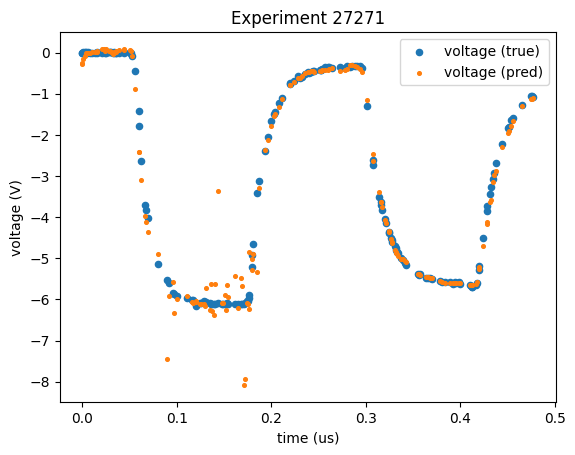

Training Test Error Rates: [1.607]


In [3]:
def perform_training(kan_width, kan_grid, kan_k, LOO = False):

    # IF something does not work, the bias is being used to scale down voltage and then scale it up again in plotting.
    # add a  #  to a row to make the training stop early
    if LOO:
        filename = "LOO_training_subsets.csv"
        subsets_df = pd.read_csv(filename)
        train_these = subsets_df.drop(columns=["Name", "Test", "Reasoning"]).to_numpy().tolist()
        test_these = subsets_df["Test"]
        
    else:
        filename = "training_subsets.csv"
        subsets_df = pd.read_csv(filename)
        train_these = subsets_df.drop(columns=["Name", "Reasoning"]).to_numpy().tolist()


    final_train_losses = []
    final_test_losses = []
    new_file_row_count = 0
    for idx, i in enumerate(train_these):
        if '#' in subsets_df["Name"].iloc[idx]: 
            print(f"Terminated early at index {idx}")
            break
        print(f"Processing experiment {i}...")
        new_file_row_count += 1
        #reset variables
        all_time = np.array([], dtype = "float32")
        time_mx_mn = [6.5, 0.0]
        all_PCD = np.array([], dtype = "float32")
        PCD_mx_mn = [0.0, 0.0]
        all_volt = np.array([], dtype = "float32")
        volt_mx_mn = [15.0, -10.0]
        all_bias = np.array([], dtype = "float32")
        bias_mx_mn = [5.25, 0]
        all_load = np.array([], dtype = "float32")
        load_mx_mn = [6,1.6989]

        train_losses = []
        test_losses = []
        train_ratio = 0.7  # Use 70% of the data for training
        if any(item in i for item in [27277, 27292, 27293, 27306]): 
            print(f"This subset {i} has an unusable experiment. Skipping")
        else:
            expmnt = i


            M1, data1, expmnt_size = train_model(expmnt, kan_width, kan_grid, kan_k, all_time, all_PCD, all_volt, all_bias, 
                                                all_load, time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn,
                                                train_losses, test_losses, train_ratio, LOO_test = LOO)
            final_train_losses.append(round(float(test_losses[-1])*100,3)) # already in percentage form and rounded
            nrmse = plot_results(M1, data1, time_mx_mn, PCD_mx_mn, volt_mx_mn, expmnt, expmnt_size, train_ratio)
            
            if LOO:
                final_test_losses.append(single_test(M1, subsets_df["Test"].iloc[idx],
                                                     time_mx_mn, PCD_mx_mn, volt_mx_mn, bias_mx_mn, load_mx_mn))

    train_loss_df = pd.DataFrame({"Name"  : subsets_df["Name"].iloc[:new_file_row_count], 
                                    "Error" : final_train_losses,
                                    "Reasoning": subsets_df["Reasoning"].iloc[:new_file_row_count]})
    train_loss_df.to_csv(f"final_train_loss_{kan_width[1][0]}.csv", index=False) # for some reason its making nested lists.
    print(f"Training Test Error Rates: {final_train_losses}")
    if LOO:
        print(f"LOO Testing Error Rates: {final_test_losses}")
        plt.scatter(range(len(final_test_losses)),final_test_losses)
        plt.title("LOO Test Errors")
        plt.xlabel("Trial")
        plt.ylabel("NRMSE in %")
        plt.show()



perform_training([4,8,8,1], 30, 3)



In [4]:

def perform_LOO_training():
    subsets_df = pd.read_csv("training_subsets.csv")
    LOO_subsets_df = pd.DataFrame(columns=["Name", "Exp01", "Exp02", "Exp03", "Exp04", "Exp05", "Test", "Reasoning"])

    for i in range(subsets_df.shape[0]):
        row = subsets_df.iloc[i,:].to_list()
        if row[3] == 0: continue # make sure experiment has at least 3 experiments
        for j in row[1:-1]:
            if j == 0: continue
            train = row[1:-1]
            train.remove(j)
            new_row = [row[0]]
            new_row += train
            new_row += [int(j), row[-1]]
            LOO_subsets_df.loc[len(LOO_subsets_df)] = new_row
    
    LOO_subsets_df.to_csv("LOO_training_subsets.csv", index = False)

    perform_training([4,8,8,1], 6, 3, True)


 
#perform_LOO_training()

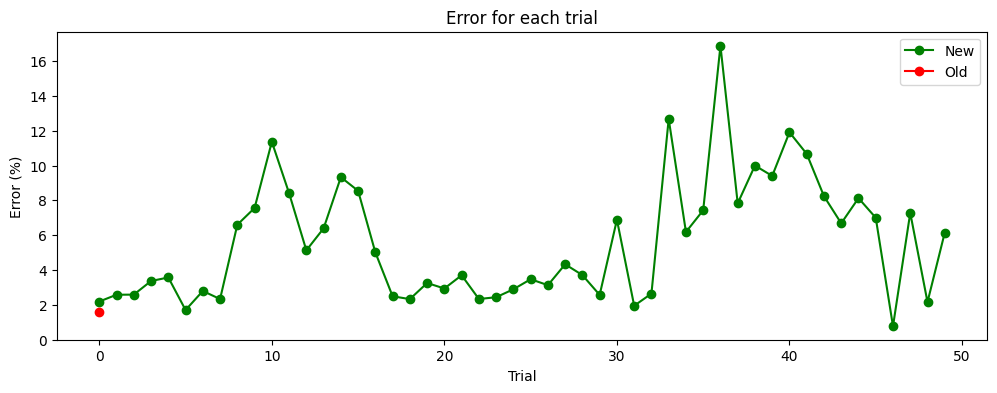

In [5]:
plot_losses(["final_train_loss_8_new.csv","final_train_loss_8.csv"], [[5,8,1],[4,8,1]])